In [1]:
#Jonathan Borowsky
#Grabe lab
#01/28/26

#rotamer calculation for collaboration with Rutter lab
#this notebook was used to develop the contents of x01_threonine_rotamers.py

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import MDAnalysis as mda
from MDAnalysis.analysis import dihedrals
from MDAnalysis.analysis.hydrogenbonds.hbond_analysis import HydrogenBondAnalysis as HBA

#import compute_observable_on_trjs_x01_v3

In [3]:
#-------------------------------- select residues -------------------------------

whichprotein = "ucp1"
whichresidue = "thr"

location_type_info = [
    "on a helix facing the membrane core",
    "on a helix facing water or headgroups",
    "on a helix N terminal with no helix carbonyl to hydrogen bond with (variable solvation)",
    "on a loop (all of these are in water)"
]

#note that these are the residue numbers; which are one larger than the indices
threonines_ucp1 = [[193, 189, 121, 30, 122, 35],[226, 103, 97, 237, 259, 165, 166, 67, 62],[176, 177, 170, 156, 133, 60, 264],[11, 48, 108, 154]]
threonines_aac1 = [[23,125,161,196,218,232],[83,138,220],[253],[154,251]]
serines_ucp1 = [[18, 86, 89, 217, 279],[87, 183, 229],[114, 230, 273],[49, 50, 75, 111, 144, 242, 249, 296, 298]]
serines_aac1 = [[],[21, 118, 126, 166, 227],[6,68,179,212,275],[1,41,45,241]]
valines_ucp1 = [[282, 286, 216, 192, 184, 125, 127, 98, 28, 136, 235, 257, 64, 65],[38, 42, 138, 135, 202, 234],[211, 14, 271, 57, 232, 250],[51]]
valines_aac1 = [[16, 31, 37, 57, 77, 180, 193, 219, 222, 226, 233, 277, 286],[25, 58, 130, 288],[178, 211, 254],[102, 144, 207, 297]]

if whichresidue == "thr":
    if whichprotein == "aac1":
        residues_byloc = threonines_aac1
        offset = 1
    elif whichprotein == "ucp1":
        residues_byloc = threonines_ucp1
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        # return 0
    
elif whichresidue == "ser":
    if whichprotein == "aac1":
        residues_byloc = serines_aac1
        offset = 1
    elif whichprotein == "ucp1":
        residues_byloc = serines_ucp1
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        # return 0

elif whichresidue == "val":
    if whichprotein == "aac1":
        residues_byloc = valines_aac1
        offset = 1
    elif whichprotein == "ucp1":
        residues_byloc = valines_ucp1
        offset = 9
    else:
        print(f"invalid protein {whichprotein}")
        # return 0

else:
    print(f"invalid protein {whichresidue}")
    # return 0  

#if residues_byloc == []:
    # return 0

#get residue indices matching mdanalysis object (0-indexed rather than using the PDB numbering)
residue_inds_byloc = [[ii-offset for ii in i] for i in residues_byloc]

#determine array dimensions necessary to encode residues in all location types in a single rectilinear numpy array
# this array is padded with values of 400 (outside the angle range returned by the dihedral calculation) 
# where there are not enough residues in a particular location type
n_loctypes = len(residues_byloc)
n_resis_per_loctype = max(len(lst) for lst in residues_byloc)

In [4]:
#-------------------------------- load trajectory -------------------------------

toppath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/input/topol.top"
trjpath = f"/home/jonathan/Documents/grabelab/rutter-lab-collaboration/test_trj/{whichprotein}/traj_comp.part0001-centered.xtc"
u = mda.Universe(toppath, trjpath, topology_format='ITP')
protein_trj = u.select_atoms('protein')

n_frames = len(u.trajectory)

/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/topology/ITPParser.py:646: DeprecationWarning: The elements attribute has been populated by guessing elements from atom types. This behaviour has been temporarily added to the ITPParser as we transition to the new guessing API. This behavior will be removed in release 3.0. Please see issue #4698 for more information. 
  warnings.warn(


In [5]:
#                             CONSISTENCY TESTS

#---------------------------------------------------------------------------------------
#print pymol query for visual verification of correct residue assignment

colors = ["o","y","c","w"]

cmd = f"hide everything; show cart, poly; show sticks, poly and not elem h; show spheres, resn {whichresidue} and not elem H; util.cbag; util.cbam resn {whichresidue}; "

for c, s in zip(colors, residues_byloc):
    if len(s) > 0:
        cmd += f'util.cba{c} resi ' + "+".join([str(i) for i in s]) + "; "

print(cmd)

#---------------------------------------------------------------------------------------
#verify consistency of residues to be analyzed and input structure

flat_resis = np.array([si for s in residue_inds_byloc for si in s])
flat_resis.flatten()

#check for duplicated residue assignments
duplicates = (len(flat_resis) != len(np.unique(flat_resis)))
if duplicates:
    print("error: residue list includes residues multiple times")

#check for residue indices corresponding to the wrong residue
all_correct_resn = np.all([res.resname == whichresidue.upper() for res in protein_trj.residues[flat_resis]])
if not all_correct_resn:
    print(f"error: residue list contains residues other than {whichresidue}")

#check of missing residue assignments
total_resis = len([res.resname for res in protein_trj.residues if res.resname.lower() == whichresidue])
if total_resis > len(np.unique(flat_resis)):
    print(f"error: not all {whichresidue} residues are listed")
elif total_resis < len(np.unique(flat_resis)):
    print(f"error: more residues are listed than exist in the protein")    


hide everything; show cart, poly; show sticks, poly and not elem h; show spheres, resn thr and not elem H; util.cbag; util.cbam resn thr; util.cbao resi 193+189+121+30+122+35; util.cbay resi 226+103+97+237+259+165+166+67+62; util.cbac resi 176+177+170+156+133+60+264; util.cbaw resi 11+48+108+154; 


In [6]:
#for debugging
# thr_inds = threonine_inds_byloc[0]
# for r in protein_trj.residues[thr_inds]:
#     print(r)

In [13]:
inds_all = []

for loc_ind in range(n_loctypes):
    resi_inds = residue_inds_byloc[loc_ind]
    r=u.residues[resi_inds]
    inds_all += [[a.index for a in ag.atoms if a.name == "OG1"][0] for ag in r]
    print([[a.index for a in ag.atoms if a.name == "OG1"][0] for ag in r])

    # #see https://userguide.mdanalysis.org/1.1.1/examples/analysis/structure/dihedrals.html
    # chi1_atoms = [res.atoms.name for res in protein_trj.residues[resi_inds].residues]

    # print(chi1_atoms)



[2825, 2761, 1702, 305, 1716, 384]
[3323, 1452, 1351, 3482, 3830, 2393, 2407, 884, 806]
[2555, 2569, 2462, 2241, 1863, 773, 3894]
[39, 586, 1520, 2220]


In [8]:
print(u.select_atoms('resname THR'))
print(u.select_atoms('resname THR and name HG1'))


<AtomGroup [<Atom 34: N of type NH1 of resname THR, resid 11 and segid PROA>, <Atom 35: HN of type H of resname THR, resid 11 and segid PROA>, <Atom 36: CA of type CT1 of resname THR, resid 11 and segid PROA>, ..., <Atom 3900: HG23 of type HA3 of resname THR, resid 264 and segid PROA>, <Atom 3901: C of type C of resname THR, resid 264 and segid PROA>, <Atom 3902: O of type O of resname THR, resid 264 and segid PROA>]>
<AtomGroup [<Atom 41: HG1 of type H of resname THR, resid 11 and segid PROA>, <Atom 307: HG1 of type H of resname THR, resid 30 and segid PROA>, <Atom 386: HG1 of type H of resname THR, resid 35 and segid PROA>, ..., <Atom 3484: HG1 of type H of resname THR, resid 237 and segid PROA>, <Atom 3832: HG1 of type H of resname THR, resid 259 and segid PROA>, <Atom 3896: HG1 of type H of resname THR, resid 264 and segid PROA>]>


11+48+154+177
108+237+48+259+170+177


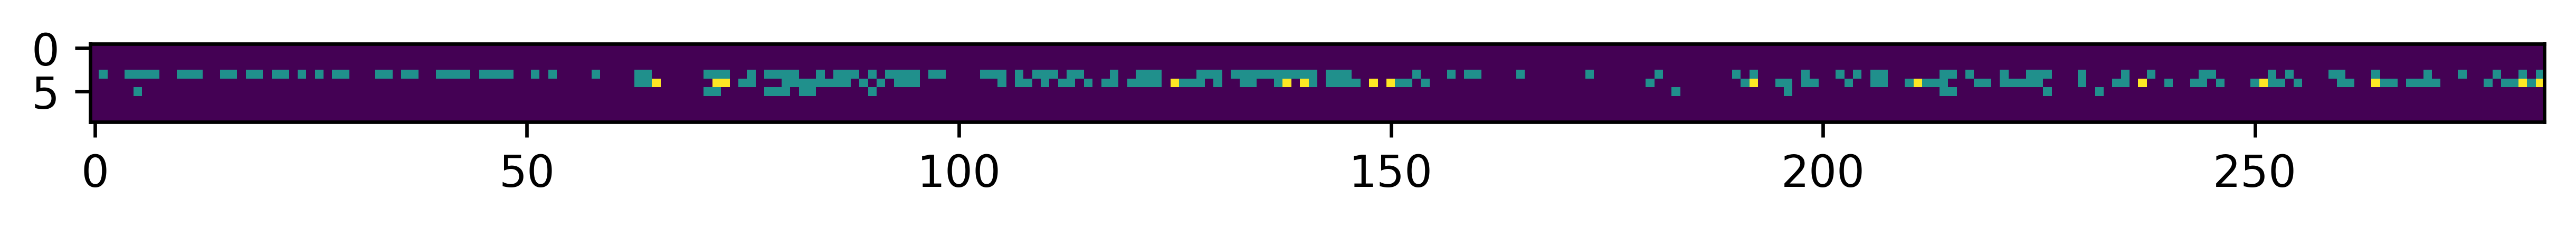

[  0.   0.   0. 119. 118.  15.   0.   0.   0.]


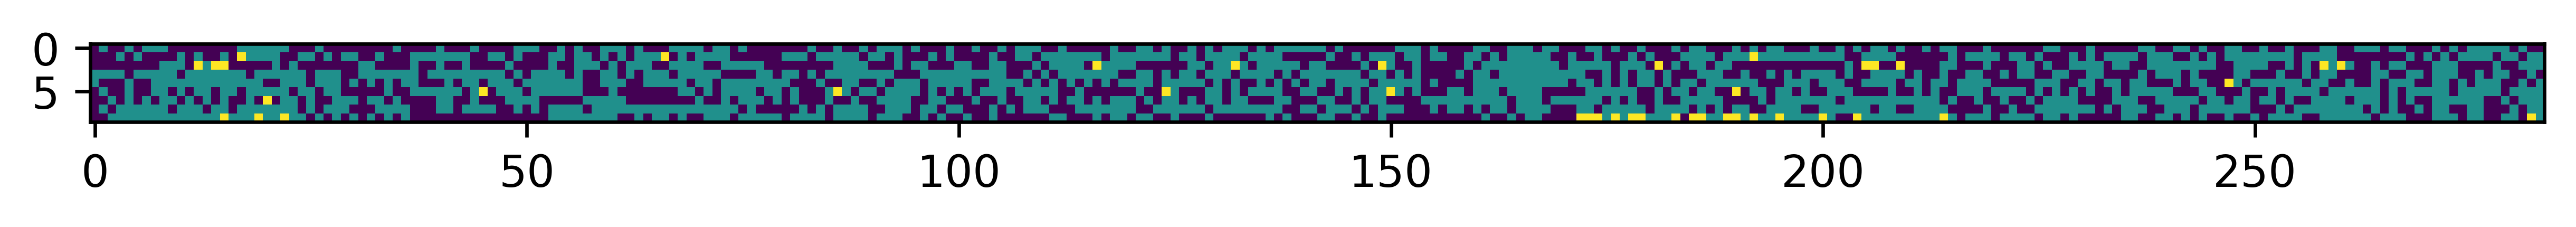

[121. 169. 150. 180. 184. 170. 161. 187. 184.]


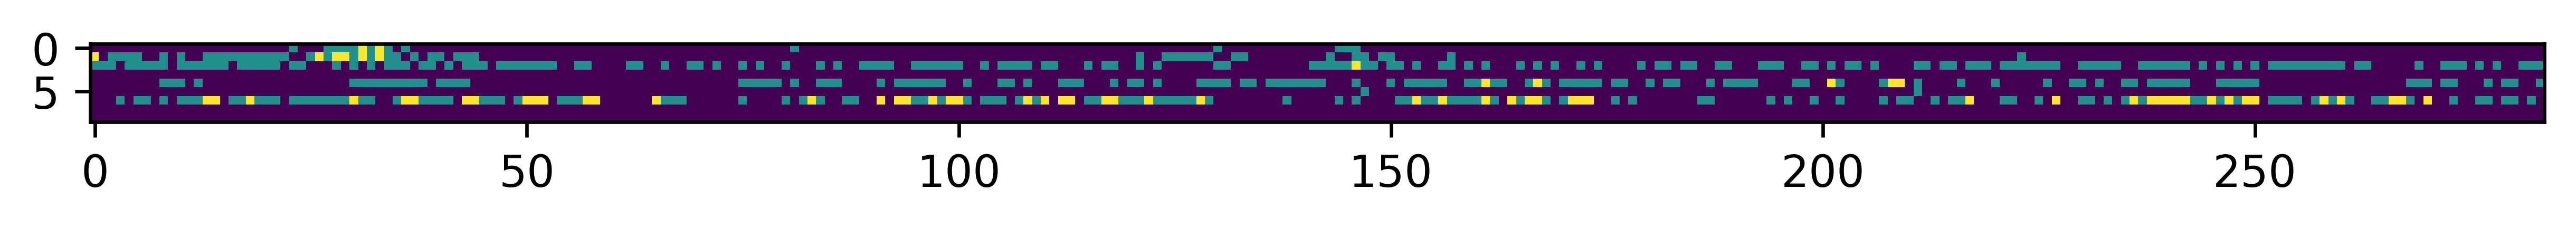

[ 17.  56. 163.   0. 127.   2. 229.   0.   0.]


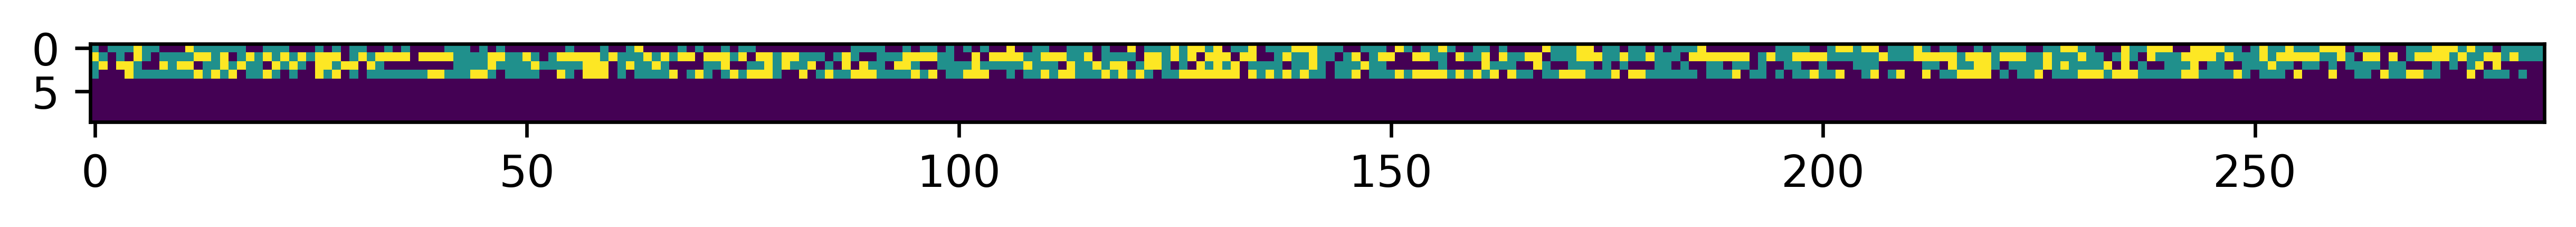

[215. 382. 245. 315.   0.   0.   0.   0.   0.]


In [47]:
#-------------------------------- calculate hydrogen bonds -------------------------------


h1 = HBA(universe=u, hydrogens_sel="resname THR and name HG1", acceptors_sel="resname TIP3 and name OH2", update_selections=False)
h1.run()

# print(h1.results.hbonds)

h2 = HBA(universe=u, hydrogens_sel="resname TIP3 and name H1 H2", acceptors_sel="resname THR and name OG1", update_selections=False)
h2.run()

# print(h2.results.hbonds)

#-------------------------------- visualize hydrogen bonds in initial frame -------------------------------
resis_flat = [r for rl in residues_byloc for r in rl]
# print(resis_flat)

hi1 = []
hi2 = []

for hi in h1.results.hbonds:
    if hi[0] == 0:
        hi1.append(str(resis_flat[inds_all.index(int(hi[1]))]))
for hi in h2.results.hbonds:
    if hi[0] == 0:
        hi2.append(str(resis_flat[inds_all.index(int(hi[3]))]))

print("+".join(hi1))
print("+".join(hi2))

#-------------------------------- count hydrogen bonds by residue -------------------------------


#number of hydrogen bonds by frame and residue
hbonds_all = np.zeros((n_loctypes, n_resis_per_loctype, n_frames))

for loc_ind in range(n_loctypes):
    resi_inds = residue_inds_byloc[loc_ind]
    r=u.residues[resi_inds]
    donor_inds = [[a.index for a in ag.atoms if a.name == "HG1"][0] for ag in r]
    acceptor_inds = [[a.index for a in ag.atoms if a.name == "OG1"][0] for ag in r]

    for ai in acceptor_inds:
        resi_num = acceptor_inds.index(ai)
        times_1 = h1.results.hbonds[np.where(h1.results.hbonds[:,1].astype(int)==ai),0].astype(int)
        for t1 in times_1:
            hbonds_all[loc_ind, resi_num, t1] += 1 

        times_2 = h2.results.hbonds[np.where(h2.results.hbonds[:,3].astype(int)==ai),0].astype(int)
        for t2 in times_2:
            hbonds_all[loc_ind, resi_num, t2] += 1 

        # print(np.where(h1.results.hbonds[:,1].astype(int)==ai))
        # print(np.where(h2.results.hbonds[:,3].astype(int)==ai))
    plt.figure(figsize=(10,10), dpi=600)
    plt.imshow(hbonds_all[loc_ind])
    plt.show()

    print(np.sum(hbonds_all[loc_ind], axis = 1))

#print(hbonds_all)

    #print(inds)


#thr_wat = mda.Merge(u.select_atoms('resname TIP3 or resname THR'), trjpath)
# for r in thr_wat.residues:
#     if r.resname != "TIP3":
#         print(r)
#print(len(thr_wat.trajectory))
#array to hold results for all threonines 
#of shape [number of location types, maximum number of residues at any one location type, number of frames]


# print(angles_all.shape)

#for loc_ind in range(n_loctypes):
# loc_ind=0
# resi_inds = residue_inds_byloc[loc_ind]

#    break

In [27]:
h1.results.hbonds[:,1].astype(int)

array([  39,  586, 2220, 2569,  586, 1520,   39, 2569,   39,  586, 1520,
       2569,   39, 1520, 2220, 2569,   39,  586, 1520, 2220, 2569,   39,
        586, 3894,   39,  806,  586, 1351, 1520, 2569,  586, 1351, 1520,
        586, 1351, 1520, 2569,   39, 1520,   39,  586, 1351, 1452, 2220,
       3894,  586, 1351, 2569, 3894,  586, 1351, 2220, 2569, 3894,  586,
        806, 1351, 1452, 1520, 2220, 2569, 2220, 2569, 3894, 1452, 1520,
       2569,  586, 2220, 2569, 3894,  806, 1452, 1520, 2220, 2569, 3894,
        586,  806, 1452, 2220, 2407, 2569,  806, 1520, 2220, 2569, 3894,
        586,  806, 1520, 2569,  806, 1520, 2555, 3894,  586,  806, 1520,
       3894, 2569, 3894,  586, 1520, 2220, 2569, 3894,  586, 1520, 2220,
       2555, 2569,  586, 1520, 2220, 2555, 2569, 1520, 2555, 2569,  586,
       1520, 2220, 2555, 2569, 3894,  586, 1351, 2555, 2569, 3894, 1520,
       2555, 2569,  586, 2220, 2555, 2569,  586, 2555, 2569,  586, 2220,
       3894,  586, 2220, 2555, 3894, 2220, 3894,  5

In [16]:
print(np.sort(np.unique(h2.hbonds[:,3])).astype(int))
print(np.sort(inds_all))

[  39  305  384  586  773  806  884 1351 1452 1520 1716 1863 2220 2393
 2407 2462 2555 2569 3323 3482 3830 3894]
[  39  305  384  586  773  806  884 1351 1452 1520 1702 1716 1863 2220
 2241 2393 2407 2462 2555 2569 2761 2825 3323 3482 3830 3894]


/home/jonathan/anaconda3/envs/serpents/lib/python3.11/site-packages/MDAnalysis/analysis/hydrogenbonds/hbond_analysis.py:809: DeprecationWarning: The `hbonds` attribute was deprecated in MDAnalysis 2.0.0 and will be removed in MDAnalysis 3.0.0. Please use `results.hbonds` instead.
  warnings.warn(wmsg, DeprecationWarning)


In [11]:
#-------------------------------- calculate dihedrals -------------------------------

#array to hold results for all threonines 
#of shape [number of location types, maximum number of residues at any one location type, number of frames]
angles_all = np.ones((n_loctypes, n_resis_per_loctype, n_frames))*400
print(angles_all.shape)

for loc_ind in range(n_loctypes):
    resi_inds = residue_inds_byloc[loc_ind]
    #see https://userguide.mdanalysis.org/1.1.1/examples/analysis/structure/dihedrals.html
    chi1_atoms = [res.chi1_selection() for res in protein_trj.residues[resi_inds]]
    chi1_dihedrals = dihedrals.Dihedral(chi1_atoms).run()
    dihedral_angles = chi1_dihedrals.results.angles
    angles_all[loc_ind, 0:len(resi_inds)] = dihedral_angles.transpose()


(4, 9, 284)


NameError: name 'dihedrals' is not defined

In [ ]:
#-------------------------------- digitize trajectory and calculate rotamer frequencies for each residue -------------------------------
#discretize trajectory

#mapping: 
#        a <= -120 : 0
# -120 < a <=    0 : 1
#    0 < a <=  120 : 2
#  120 < a <=  180 : 3
#  180 < a         : 4 #used to represent empty array entries (i.e. at location types with fewer residues)
angles_discrete = np.digitize(angles_all, [-120, 0, 120, 180], right=True) #this splits the rotamer centered on +-180 degrees into two bins
angles_discrete = np.where(angles_discrete == 3, 0, angles_discrete) #merge the bins for the rotamer at 180 degrees back together

#count occurrences of each rotamer
# note that due to trajectory length variability frequencies are not to be calculated until later
n_rotamers = 3
rotamer_counts = np.zeros((n_loctypes, n_resis_per_loctype, n_rotamers))

for rotamer_ind in range(n_rotamers):
    rotamers_onehot = np.where(angles_discrete == rotamer_ind, 1, 0)
    rotamer_counts[:,:,rotamer_ind] = np.sum(rotamers_onehot, axis = 2)
print(rotamer_counts)

In [ ]:
for i in angles_all[3]:
    plt.plot(i)

In [ ]:
for i in angles_discrete[3]:
    plt.plot(i)

In [ ]:
######################################################################################################
#                                               FIN
######################################################################################################